# M08-3 | XnnpackPartitioner 不收的 op：圖怎麼切、邊界長什麼樣

Partitioner 在圖上找出後端吃得下的連通子圖，每一塊編譯成一個 delegate；吃不下的 op 留在圖上，由 ExecuTorch 自己的 portable kernel（通用的 C++ 實作）執行。
M08-2 的 TinyConvNet 整張圖都進了 XNNPACK。這裡刻意在兩個 conv 中間塞一個 `cumsum`：XNNPACKQuantizer 不標它，XnnpackPartitioner 也不收它（executorch 1.5.0 實測）。

- **A.** 量化：`cumsum` 沒有標籤，在 Q/DQ 圖上跑 fp32。
- **B.** lowering：圖在 `cumsum` 前後被切成兩個 delegate，兩塊之間傳 fp32。
- **C.** 執行：`.pte` 和 Q/DQ 圖的輸出差多少。

這本 notebook 需要 executorch（`uv sync --group executorch`）。

In [1]:
import torch
import torch.nn as nn

from common.pt2e import quiet  # 必須在 executorch 之前 import
from common.env import env_summary
from common.executorch_utils import PteRunner, delegation_summary, lower_to_xnnpack, xnnpack_ptq
from common.graph_utils import op_counts, short
from common.models import example_inputs
from common.pt2e import get_xnnpack_quantizer, export_module
from common.viz import annotation_notes, draw, table

quiet()
_ = torch.manual_seed(0)
print(env_summary())

Darwin arm64｜torch 2.14.0｜threads=4｜mkldnn=False｜nnpack=True


In [2]:
class ConvCumsumConv(nn.Module):
    """conv → relu → cumsum → conv。cumsum 沿 channel 累加。"""

    def __init__(self, ch=8):
        super().__init__()
        self.conv1 = nn.Conv2d(3, ch, 3, padding=1)
        self.conv2 = nn.Conv2d(ch, ch, 3, padding=1)

    def forward(self, x):
        y = torch.relu(self.conv1(x))
        y = torch.cumsum(y, dim=1)
        return self.conv2(y)


model = ConvCumsumConv().eval()
x = example_inputs(1)

## A. 量化：`cumsum` 沒有標籤

先只看標籤：export 之後呼叫 executorch 版 XNNPACKQuantizer 的 `annotate`，標籤畫在 node 底下（M03-2）：

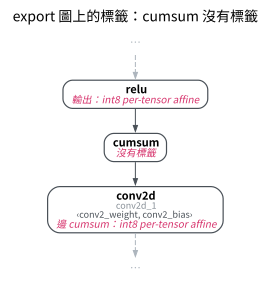

In [3]:
labeled = export_module(model, x, dynamic_batch=False)
get_xnnpack_quantizer("executorch", is_per_channel=True)[0].annotate(labeled)
notes = annotation_notes(labeled, unlabeled=True)
draw(labeled, focus=["relu", "cumsum", "conv2d_1"], hops=0,
     notes={k: notes[k] for k in ["relu", "cumsum"]} | {"conv2d_1": notes["conv2d_1"].split("\n")[0]},
     title="export 圖上的標籤：cumsum 沒有標籤")

XNNPACKQuantizer 沒有 cumsum 的 annotator，所以 cumsum 沒有標籤（M03-6 的 fallback）。它的上下游都有標籤：relu 的輸出要量化（conv-relu 的輸出），conv2d_1 的輸入邊要量化。
做完 PTQ（`xnnpack_ptq`，M08-2）之後，cumsum 前後各一對 q/dq：

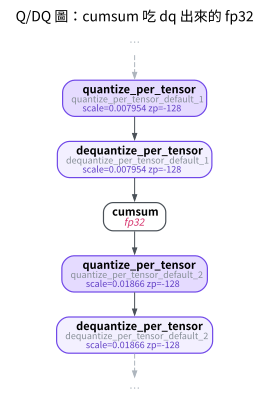

In [4]:
qdq = xnnpack_ptq(model, x)
draw(qdq, focus="cumsum", hops=2, notes={"cumsum": "fp32"}, title="Q/DQ 圖：cumsum 吃 dq 出來的 fp32")

cumsum 吃 dequantize 出來的 fp32，輸出 fp32，再被量化一次給 conv2d_1。

## B. lowering：圖被切成兩個 delegate

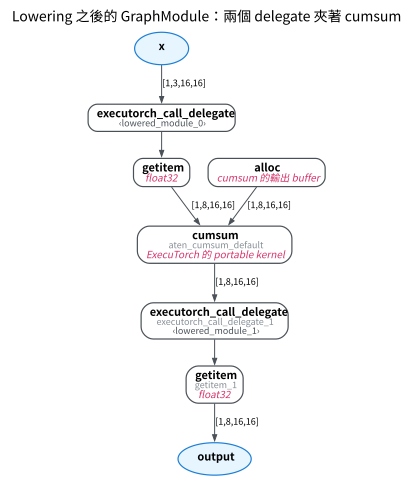

In [5]:
edge, pte = lower_to_xnnpack(qdq, x)  # 本專案的包裝：export → to_edge_transform_and_lower → to_executorch（M08-2 A）
lowered = edge.exported_program().graph_module
draw(lowered, show_shapes=True,
     notes={"aten_cumsum_default": "ExecuTorch 的 portable kernel", "alloc": "cumsum 的輸出 buffer",
            **{n.name: str(n.meta["val"].dtype).removeprefix("torch.") for n in lowered.graph.nodes
               if short(n.target) == "getitem"}},
     title="Lowering 之後的 GraphModule：兩個 delegate 夾著 cumsum")

請看兩個 `executorch_call_delegate` 之間：`getitem` 取出前一塊的輸出，交給 cumsum，cumsum 的輸出再進後一塊。邊上標的是 shape，`getitem` 底下標的是它輸出的 dtype（取自 `node.meta["val"]`）：float32。
cumsum 前後的 dq、q 被收進兩邊的 delegate，前一塊最後把 int8 轉回 fp32，後一塊開頭再轉成 int8。

`alloc` 是 `to_executorch()` 替 cumsum 事先配好的輸出 buffer（memory planning，M08-2 C），`getitem` 從 delegate 的輸出 tuple 取值，兩者都不是運算。

用 `delegation_summary` 數每個 op 的去向：

In [6]:
n_sub, n_del, n_non, by_op = delegation_summary(edge)
table([[op, d, nd] for op, (d, nd) in sorted(by_op.items())], ["op（Edge dialect 名稱）", "交給 XNNPACK", "留在 ExecuTorch"])

op（Edge dialect 名稱）,交給 XNNPACK,留在 ExecuTorch
alloc,0,1
aten_convolution_default,2,0
aten_cumsum_default,0,1
aten_relu_default,1,0
getitem,0,2
quantized_decomposed_dequantize_per_channel_default,2,0
quantized_decomposed_dequantize_per_tensor_default,4,0
quantized_decomposed_quantize_per_tensor_default,4,0


In [7]:
n_before = sum(op_counts(qdq).values())
left = {op: nd for op, (_, nd) in by_op.items() if nd}
print(f"delegate {n_sub} 個；Q/DQ 圖的 {n_before} 個 op 中，{n_del} 個進了 delegate；留下：{left}")
assert n_sub == 2 and n_del == n_before - 1 and set(left) == {"aten_cumsum_default", "alloc", "getitem"}
assert all(n.meta["val"].dtype == torch.float32 for n in lowered.graph.nodes if short(n.target) == "getitem")  # 邊界傳 fp32

delegate 2 個；Q/DQ 圖的 14 個 op 中，13 個進了 delegate；留下：{'getitem': 2, 'alloc': 1, 'aten_cumsum_default': 1}


Q/DQ 圖上只有 cumsum 沒進 delegate，其餘留下的都是 lowering 新增的 `alloc`、`getitem`。
每多一個邊界，就多一次 int8 ↔ fp32 轉換，以及一次 ExecuTorch 與 XNNPACK 之間的往返。

量化前用標籤確認「哪些 op 沒被標」（M03-2），部署前用這張表確認「哪些 op 沒進 delegate」。兩者是獨立的決定：

| 誰決定 | 不支援時 |
|---|---|
| quantizer 標不標 | 沒標的 op 在 Q/DQ 圖上跑 fp32 |
| partitioner 收不收 | 不收的 op 留在 delegate 外，跑 ExecuTorch 的 portable kernel |

## C. 執行：`.pte` 和 Q/DQ 圖的輸出

`.pte` 只吃匯出時的 batch 1（M08-2 C），所以 64 筆隨機輸入一次餵一筆：

In [8]:
runner = PteRunner(pte)
xs = torch.randn(64, 3, 16, 16)
with torch.no_grad():
    y_pte = torch.cat([runner(xs[i : i + 1]) for i in range(len(xs))])
    y_qdq = torch.cat([qdq(xs[i : i + 1]) for i in range(len(xs))])
lsb = [n for n in qdq.graph.nodes if short(n.target) == "quantize_per_tensor"][-1].args[1]
same = (y_pte == y_qdq).float().mean().item()
max_lsb = ((y_pte - y_qdq).abs() / lsb).round().max().item()
print(f"輸出逐位元相同：{same:.2%}；最大差 {max_lsb:.0f} 個輸出 LSB（輸出 LSB = 最後一個 quantize 的 scale {lsb:.4g}）")

輸出逐位元相同：99.69%；最大差 1 個輸出 LSB（輸出 LSB = 最後一個 quantize 的 scale 0.01771）


In [9]:
assert max_lsb <= 2

切成兩塊照樣能跑。和 Q/DQ 圖的差只有幾個輸出 LSB，來自整數 kernel 的捨入（M08 概覽〈和 Q/DQ 圖的數值差異〉）。
不支援的 op 不會讓匯出失敗，只是那一段不在 XNNPACK 上跑。

## 小結

- quantizer 沒標的 op 跑 fp32；partitioner 不收的 op 留在 delegate 外，跑 ExecuTorch 的 portable kernel。
- 不支援的 op 夾在中間會把圖切開，邊界上傳 fp32，多出 int8 ↔ fp32 轉換與 runtime 往返。
- 部署前用 `get_delegation_info`（`delegation_summary`）確認哪些 op 沒進 delegate。